In [1]:
from pathlib import Path
import sys
import json
import os
import matplotlib.pyplot as plt

RESULTS_DIR = Path.cwd()
sys.path.append(str(RESULTS_DIR))

In [2]:
results_path = results_file = next((f for f in os.listdir(RESULTS_DIR) if 'results' in f), None)
if results_path:
    with open(RESULTS_DIR / results_path, 'r') as f:
        gsm8k_scores = [json.loads(line) for line in f]
else:
    gsm8k_scores = None

In [3]:
# Extract unique model collections
models_collection = set()
for score in gsm8k_scores:
    exp_name = score['experiment_name'].split('/')[0]
    if 'finetuned' not in exp_name:
        models_collection.add(exp_name)

# Prepare data structures for both metrics
data_strict = { exp: {} for exp in models_collection }
data_strict_stderr = { exp: {} for exp in models_collection }
data_flexible = { exp: {} for exp in models_collection }
data_flexible_stderr = { exp: {} for exp in models_collection }

checkpoint_steps = [str(i) for i in range(1000, 10001, 1000)]

for collection in models_collection:
    for experiment in gsm8k_scores:
        exp_name = experiment['experiment_name'].split('/')[0]
        # Exact match on the collection name (before the '/')
        if exp_name == collection:
            step = experiment['experiment_name'].split('-')[-1]
            if step in checkpoint_steps:
                data_strict[collection][int(step)] = experiment['exact_match,strict-match']
                data_strict_stderr[collection][int(step)] = experiment['exact_match_stderr,strict-match']
                data_flexible[collection][int(step)] = experiment['exact_match,flexible-extract']
                data_flexible_stderr[collection][int(step)] = experiment['exact_match_stderr,flexible-extract']

# Find experiment ending with 'finetuned'
finetuned_exp = next((exp for exp in gsm8k_scores if exp['experiment_name'].endswith('finetuned')), None)

# Find experiment ending with 'pretrained'
pretrained_exp = next((exp for exp in gsm8k_scores if exp['experiment_name'].endswith('pretrained')), None)

if finetuned_exp:
    data_strict['finetuned'] = finetuned_exp['exact_match,strict-match']
    data_strict_stderr['finetuned'] = finetuned_exp['exact_match_stderr,strict-match']
    data_flexible['finetuned'] = finetuned_exp['exact_match,flexible-extract']
    data_flexible_stderr['finetuned'] = finetuned_exp['exact_match_stderr,flexible-extract']
    
if pretrained_exp:
    data_strict['pretrained'] = pretrained_exp['exact_match,strict-match']
    data_strict_stderr['pretrained'] = pretrained_exp['exact_match_stderr,strict-match']
    data_flexible['pretrained'] = pretrained_exp['exact_match,flexible-extract']
    data_flexible_stderr['pretrained'] = pretrained_exp['exact_match_stderr,flexible-extract']

In [4]:
models_collection

{'Llava1.5-7B', 'Llava1.5-7B-18-32', 'Llava1.5-7B-2-18', 'Llava1.5-7B-frozen'}

In [5]:
basename = "Llava1.5-7B"
NAMES_MAPPING = {
    basename: "full",
    f"{basename}-2-18": "2-18",
    f"{basename}-18-32": "18-32",
    # f"{basename}-2-2": "2-2",
    f"{basename}-frozen": "frozen_llm",
    "finetuned": "FM",
    "pretrained": "PM"
}

COLOR_SCHEME = {
    'full': '#08519c',      # Dark blue - all layers fine-tuned
    '2-18': '#6baed6',      # Medium blue - early-upper layers
    '18-32': '#9ecae1',     # Light blue - upper layers only
    # '2-2': '#c6dbef',     # Very light blue - middle layers (reserved)
    'frozen_llm': '#006d2c',   # Dark green - frozen projector, all LLM layers trained
    'PM': 'black',
    'FM': 'red',
}

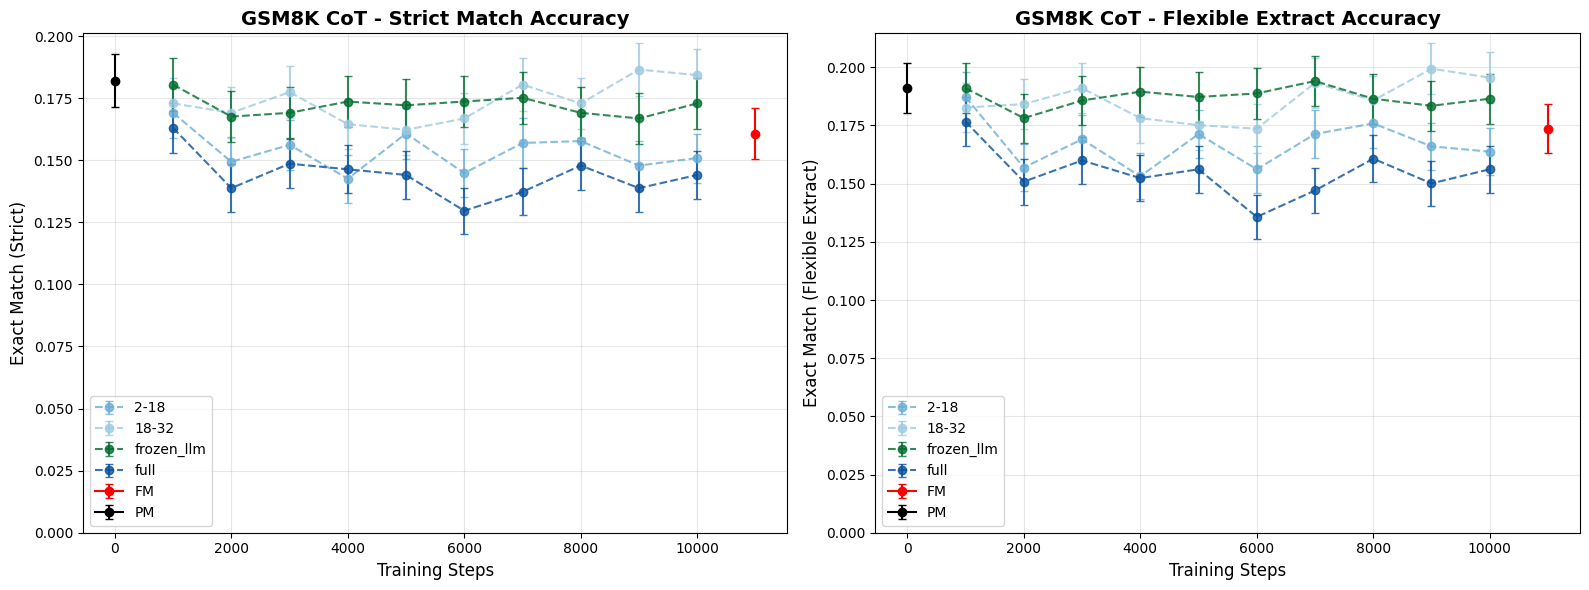

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left plot: Strict Match Accuracy
ax = axes[0]
for collection in models_collection:
    label = NAMES_MAPPING.get(collection, collection)
    color = COLOR_SCHEME.get(label, "#000000")
    if data_strict[collection]:  # Only plot if there's data
        steps, scores = zip(*sorted(data_strict[collection].items()))
        _, stderrs = zip(*sorted(data_strict_stderr[collection].items()))
        ax.errorbar(
            steps,
            scores,
            yerr=stderrs,
            label=label,
            color=color,
            marker="o",
            linestyle="--",
            capsize=3,
            alpha=0.8
        )

if "finetuned" in data_strict:
    label = NAMES_MAPPING.get("finetuned", "finetuned")
    color = COLOR_SCHEME.get(label, "red")
    ax.errorbar(
        11000, 
        data_strict["finetuned"], 
        yerr=data_strict_stderr["finetuned"],
        label=label, 
        color=color, 
        marker="o",
        capsize=3
    )

if "pretrained" in data_strict:
    label = NAMES_MAPPING.get("pretrained", "pretrained")
    color = COLOR_SCHEME.get(label, "green")
    ax.errorbar(
        0, 
        data_strict["pretrained"], 
        yerr=data_strict_stderr["pretrained"],
        label=label, 
        color=color, 
        marker="o",
        capsize=3
    )

ax.set_ylim(ymin=0)
ax.set_xlabel("Training Steps", fontsize=12)
ax.set_ylabel("Exact Match (Strict)", fontsize=12)
ax.set_title("GSM8K CoT - Strict Match Accuracy", fontsize=14, fontweight='bold')
ax.legend(loc='best')
ax.grid(True, alpha=0.3)

# Right plot: Flexible Extract Accuracy
ax = axes[1]
for collection in models_collection:
    label = NAMES_MAPPING.get(collection, collection)
    color = COLOR_SCHEME.get(label, "#000000")
    if data_flexible[collection]:  # Only plot if there's data
        steps, scores = zip(*sorted(data_flexible[collection].items()))
        _, stderrs = zip(*sorted(data_flexible_stderr[collection].items()))
        ax.errorbar(
            steps,
            scores,
            yerr=stderrs,
            label=label,
            color=color,
            marker="o",
            linestyle="--",
            capsize=3,
            alpha=0.8
        )

if "finetuned" in data_flexible:
    label = NAMES_MAPPING.get("finetuned", "finetuned")
    color = COLOR_SCHEME.get(label, "red")
    ax.errorbar(
        11000, 
        data_flexible["finetuned"], 
        yerr=data_flexible_stderr["finetuned"],
        label=label, 
        color=color, 
        marker="o",
        capsize=3
    )

if "pretrained" in data_flexible:
    label = NAMES_MAPPING.get("pretrained", "pretrained")
    color = COLOR_SCHEME.get(label, "green")
    ax.errorbar(
        0, 
        data_flexible["pretrained"], 
        yerr=data_flexible_stderr["pretrained"],
        label=label, 
        color=color, 
        marker="o",
        capsize=3
    )

ax.set_ylim(ymin=0)
ax.set_xlabel("Training Steps", fontsize=12)
ax.set_ylabel("Exact Match (Flexible Extract)", fontsize=12)
ax.set_title("GSM8K CoT - Flexible Extract Accuracy", fontsize=14, fontweight='bold')
ax.legend(loc='best')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()